# **Task 1: tabular supervised classification**

Train a classification model using the public training data and generate predictions for the held-out feature rows.

Output contract:

* Input file: dataset/task1/test_features.csv

* Required output file: outputs/task1_predictions.csv

* Required columns: patient_id, prediction

* The output must contain exactly one row for every row in test_features.csv, with matching patient IDs and no missing values.

The submitted solution must be your-sollution/task1_solution.py or your-sollution/task1_solution.ipynb.

**Задача: бинарная классификация — предсказать Доклинический_риск (0/1)
на табличных медицинских данных.**

Решаем нейронной сетью прямого
распространения (как на семинаре в блоке "Задача классификации" на breast_cancer)

**1. Импорты библиотек** (*pandas/numpy* для табличных данных, *sklearn* для split, нормализации и метрик, *torch* для нейросети, оптимизации и DataLoader, *os* чтобы создать папку outputs, *matplotlib* для графика потерь)

In [20]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import matplotlib.pyplot as plt

**2. Загрузка данных**

Читаем train.csv *(там есть и признаки, и целевая переменная, и колонка prediction)* и test_features.csv *(там только признаки, без целевой переменной)*. **Колонка prediction в train это готовая чужая метка, поэтому её нельзя использовать как признак, иначе модель выучит чужой ответ.**

Поэтому формируем список признаков как по принципу "все колонки, кроме patient_id, Доклинический_риск и prediction"

In [21]:
train_df = pd.read_csv("/content/train.csv")
test_df = pd.read_csv("/content/test_features.csv")

TARGET = "Доклинический_риск"
ID_COL = "patient_id"

#в train колонка "prediction" это чужая готовая метка (утечка), поэтому она исключается из признаков
DROP_COLS = [ID_COL, TARGET, "prediction"]

feature_cols = [c for c in train_df.columns if c not in DROP_COLS]
feature_cols = [c for c in feature_cols if c in test_df.columns]

X = train_df[feature_cols].values.astype(np.float32)
y = train_df[TARGET].values.astype(np.float32).reshape(-1, 1)

X_test_full = test_df[feature_cols].copy()
test_ids    = test_df[ID_COL].values

print(f"Признаков: {X.shape[1]}, Объектов в train: {X.shape[0]}")
print(f"Объектов в test_features: {X_test_full.shape[0]}")
print(f"Классы: 0 = нет доклинического риска, 1 = есть доклинический риск")

Признаков: 16, Объектов в train: 800
Объектов в test_features: 200
Классы: 0 = нет доклинического риска, 1 = есть доклинический риск


**3. Обработка пропусков**

В медицинских таблицах есть пропуски (ЛПНП, СКФ, ЛПВП и др.), тк нейросеть не умеет работать с NaN, я заполнила их медианой, посчитанной ТОЛЬКО на train (так мы не подглядываем в тест). Той же медианой заполняем и test_features.csv

In [22]:
for i, col in enumerate(feature_cols):
    median_val = np.nanmedian(X[:, i])
    mask = np.isnan(X[:, i])
    X[mask, i] = median_val

    # то же самое для теста, той же медианой train
    col_test = X_test_full[col].values.astype(np.float32)
    mask_test = np.isnan(col_test)
    col_test[mask_test] = median_val
    X_test_full[col] = col_test

X_test_full = X_test_full.values.astype(np.float32)
print("Пропусков после заполнения (train):", np.isnan(X).sum())
print("Пропусков после заполнения (test): ", np.isnan(X_test_full).sum())

Пропусков после заполнения (train): 0
Пропусков после заполнения (test):  0


**4. Разбиение на train/test split**

tratify=y сохраняет пропорцию классов в train и test - это важно, потому что класс 1 (доклинический риск) редкий, и без стратификации его может не оказаться в тестовой части

*80/20, random_state=42 - как на паре*

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Класс 1 в train:", int(y_train.sum()), "/", len(y_train))
print("Класс 1 в test: ", int(y_test.sum()),  "/", len(y_test))

X_train: (640, 16) | X_test: (160, 16)
Класс 1 в train: 42 / 640
Класс 1 в test:  10 / 160


**5. Нормализация признаков**

StandardScaler приводит каждый признак к среднему 0 и std 1, без этого признак с большим масштабом (СКФ ~100) подавляет признак с малым (HbA1c ~5), и ***сеть учится плохо.*** fit делаем ТОЛЬКО на train, transform на train, test и на holdout из test_features.csv (это отдельный файл, его тоже надо нормализовать)

In [24]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# те же параметры scaler применяем к test_features.csv
X_holdout = scaler.transform(X_test_full)

**6. Преобразование тензоров**

torch.tensor превращает numpy-массивы в тензоры PyTorch, dtype=torch.float32 это стандартный тип для нейросетей

In [25]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t  = torch.tensor(X_test,  dtype=torch.float32)
y_test_t  = torch.tensor(y_test,  dtype=torch.float32)

X_holdout_t = torch.tensor(X_holdout, dtype=torch.float32)

**7. DataLoader**

TensorDataset упаковывает (X, y) в пары, DataLoader подаёт их батчами (batch_size=32), Train shuffle=True перемешиваем каждый эпоху, test shuffle=False порядок не важен, нужен детерминизм

In [26]:
batch_size = 32
train_dataset = TensorDataset(X_train_t, y_train_t)
test_dataset  = TensorDataset(X_test_t,  y_test_t)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False)

print("Батчей в train:", len(train_loader))
print("Батчей в test: ", len(test_loader))

Батчей в train: 20
Батчей в test:  5


**8. Определение модели FFN**

Архитектура как BreastCancerFFN на паре, только класс назван по задаче

fc1: Linear(input_dim -> 64) + ReLU + Dropout(0.2)

fc2: Linear(64 -> 32) + ReLU

fc3: Linear(32 -> 1) - один логит, потому что для бинарной классификации достаточно одного выхода: логит > 0 -> класс 1, иначе -> класс 0. ReLU добавляет нелинейность, без неё сеть была бы одной линейной моделью.

Dropout случайно обнуляет 20% нейронов во время обучения это защита от переобучения

In [27]:
class RiskFFN(nn.Module):
  def __init__(self, input_dim):
    super().__init__()
    self.fc1 = nn.Linear(input_dim, 64)
    self.fc2 = nn.Linear(64, 32)
    self.fc3 = nn.Linear(32, 1)  # один логит для бинарной классификации
    self.relu = nn.ReLU()
    self.dropout = nn.Dropout(0.2)

  def forward(self, x):
    x = self.relu(self.fc1(x))
    x = self.dropout(x)
    x = self.relu(self.fc2(x))
    x = self.fc3(x)          # линейный выход (logits)
    return x

# определяемся, где обучать - GPU (если есть) или CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = RiskFFN(X_train.shape[1]).to(device)
print(model)
print("Устройство:", device)

RiskFFN(
  (fc1): Linear(in_features=16, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
)
Устройство: cpu


**9. Функция потерь и оптимизатор**

BCEWithLogitsLoss это устойчивая комбинация Sigmoid + BCELoss, она работает с «сырыми» логитами (без Sigmoid на выходе модели), численно стабильнее, чем считать Sigmoid и BCE отдельно

Adam это адаптивный оптимизатор, lr=0.001, он обновляет веса модели, чтобы уменьшить значение функции потерь

In [28]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

**10. Цикл обучения**

100 эпох, на каждой эпохе:
* Train: model.train() -> forward -> loss -> backward -> step, optimizer.zero_grad() обнуляет градиенты перед новым батчем, running_loss копит ошибку за эпоху.
* Validation: model.eval() + torch.no_grad() — градиенты не считаем, просто усредняем loss на тестовой части.

Каждые 20 эпох печатаем Train Loss и Test Loss

In [29]:
epochs = 100
train_losses, test_losses = [], []

for epoch in range(epochs):
    # Train
    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_batch.size(0)
    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # Validation
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            val_loss += loss.item() * X_batch.size(0)
    epoch_test_loss = val_loss / len(test_loader.dataset)
    test_losses.append(epoch_test_loss)

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{epochs} — Train Loss: {epoch_train_loss:.4f}, Test Loss: {epoch_test_loss:.4f}")

Epoch 20/100 — Train Loss: 0.1042, Test Loss: 0.1392
Epoch 40/100 — Train Loss: 0.0481, Test Loss: 0.1604
Epoch 60/100 — Train Loss: 0.0201, Test Loss: 0.2115
Epoch 80/100 — Train Loss: 0.0123, Test Loss: 0.2909
Epoch 100/100 — Train Loss: 0.0051, Test Loss: 0.3362


**11. Оценка модели**

odel.eval() выключает Dropout на инференсе, прогоняем test_loader, собираем вероятности через torch.sigmoid(outputs) и истинные метки

y_pred_class это вероятности, переведённые в 0/1 порогом 0.5

In [30]:
model.eval()
y_pred_prob = []
y_true = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        outputs = model(X_batch)
        probs = torch.sigmoid(outputs)  # вероятность класса 1
        y_pred_prob.extend(probs.cpu().numpy().flatten())
        y_true.extend(y_batch.numpy().flatten())

y_pred_prob = np.array(y_pred_prob)
y_true = np.array(y_true)
y_pred_class = (y_pred_prob >= 0.5).astype(int)

**12. Метрики**

*Accuracy* это доля правильных ответов, *Precision* это из всех предсказанных положительных, сколько действительно положительных, *Recall* это из всех реальных положительных, сколько мы нашли, *F1-score* это гармоническое среднее между Precision и Recall (полезно при дисбалансе), *ROC-AUC* это площадь под ROC-кривой - она показывает, насколько хорошо модель разделяет классы (0.5 - случайно, 1.0 - идеально)

In [31]:
print("Оценка на тестовой выборке:")
print(f"Accuracy: {accuracy_score(y_true, y_pred_class):.4f}")
print(f"Precision: {precision_score(y_true, y_pred_class, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_true, y_pred_class, zero_division=0):.4f}")
print(f"F1-score: {f1_score(y_true, y_pred_class, zero_division=0):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_true, y_pred_prob):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred_class))

Оценка на тестовой выборке:
Accuracy: 0.9437
Precision: 0.6667
Recall: 0.2000
F1-score: 0.3077
ROC-AUC: 0.9547

Confusion Matrix:
[[149   1]
 [  8   2]]


**13. График потерь**

Строим train_losses и test_losses по эпохам, по графику видно, нет ли переобучения: если train падает, а test растёт, *модель начала запоминать train вместо того, чтобы учить общие закономерности*

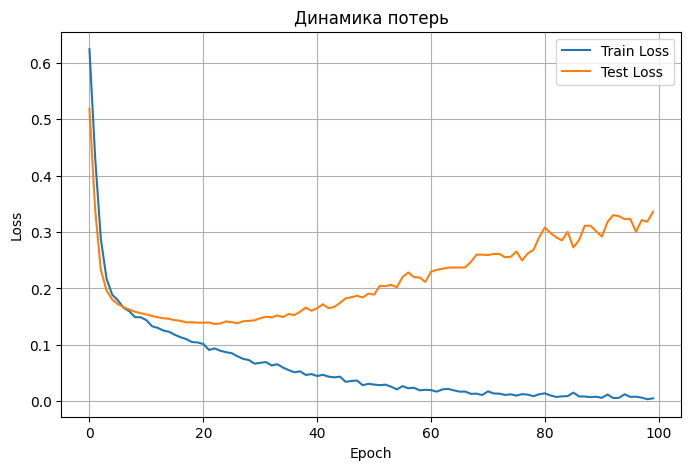

In [32]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses,  label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Динамика потерь')
plt.legend()
plt.grid(True)
plt.show()

**14. Предсказания для test_features.csv**

Тот же model.eval(), тот же torch.sigmoid, тот же порог 0.5. Подаём X_holdout_t батчами (чтобы не забить память), собираем вероятности и переводим их в 0/1

In [33]:
model.eval()
holdout_prob = []

with torch.no_grad():
    for i in range(0, len(X_holdout_t), batch_size):
        X_batch = X_holdout_t[i:i+batch_size].to(device)
        outputs = model(X_batch)
        probs = torch.sigmoid(outputs)
        holdout_prob.extend(probs.cpu().numpy().flatten())

holdout_prob = np.array(holdout_prob)
holdout_pred = (holdout_prob >= 0.5).astype(int)

print("Размер предсказаний:", holdout_pred.shape)
print("Распределение предсказаний:")
print(pd.Series(holdout_pred).value_counts())

Размер предсказаний: (200,)
Распределение предсказаний:
0    195
1      5
Name: count, dtype: int64


**15. Сохранение результата**

Нужен файл outputs/task1_predictions.csv с колонками patient_id и prediction - ровно одна строка на каждую строку test_features.csv, те же patient_id, без пропусков

In [34]:
os.makedirs("/content/outputs", exist_ok=True)

submission = pd.DataFrame({
    "patient_id": test_ids,
    "prediction": holdout_pred.astype(int),
})
submission.to_csv("/content/outputs/task1_predictions.csv", index=False)

print("Сохранено: /content/outputs/task1_predictions.csv")
print("Строк в файле:", len(submission))
print(submission.head())

Сохранено: /content/outputs/task1_predictions.csv
Строк в файле: 200
   patient_id  prediction
0           2           0
1           3           0
2           8           0
3          18           0
4          19           0
